> **Execução histórica:** estes resultados foram produzidos antes da correção da máscara SOURCE (bit 21). O flag identifica uma fonte conhecida, não um defeito. Execute novamente o comando do notebook para usar a máscara corrigida. Para o pipeline atualizado, consulte `06_sep_astrometria_psf_zogy.ipynb`.

# Comparação: Gural (2018) e Stetzler et al. (2025)

Experimentos sobre as mesmas oito exposições reais SPHEREx DR1 de 31/10/2025.
Os controles que acrescentam fontes artificiais ao fundo real são identificados
como **injeções**. Nenhum resultado aqui é um asteroide confirmado.

- **Gural:** implementação independente das equações 1–2 e busca em distância
  inversa. O software SALTAD/TGEN dos autores não está disponível no repositório
  público; não executamos esse software nem todo o pipeline do artigo.
- **Stetzler:** execução do pacote dos autores `find-asteroids`, com busca Hough
  em CPU, refinamento MCD e coleta de pontos. Os catálogos de entrada são
  extraídos dos FITS reais por máximos locais do filtro de PSF.

Referências: [Gural](https://doi.org/10.1088/1538-3873/aac1ff),
[Stetzler v1](https://arxiv.org/abs/2509.26279v1),
[código dos autores](https://github.com/stevenstetzler/find-asteroids).

In [1]:
import json
from pathlib import Path

from astropy.table import Table
from IPython.display import JSON, Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "outputs/literature"
report = json.loads((OUT / "report.json").read_text())
print(report["data"])
print("Versões:", report["versions"])
print("Asteroides confirmados:", report["confirmed_asteroids"])

Eight real SPHEREx DR1 detector 1 exposures; controls labeled as injected
Versões: {'find-asteroids': '0.1.3', 'mcd-regression': '0.1.1', 'numpy': '2.5.4', 'astropy': '8.0.2'}
Asteroides confirmados: 0


## Trajetórias com paralaxe

O movimento do observatório produz curvatura entre exposições. A hipótese linear
é comparada a cinco distâncias, incluindo o limite de distância infinita, que
corresponde ao caso sem curvatura. Mais hipóteses podem aumentar o maior escore
inclusive em ruído e resíduos; isso não é prova de uma detecção melhor.

Os eixos dos vetores GEOCENTER foram assumidos equatoriais inerciais: a origem
está documentada no cabeçalho, mas essa hipótese sobre os eixos ainda exige
verificação. A comparação é exploratória.

In [2]:
g = report["gural"]
print("Curvatura máxima a 0,4 au [pixel]:", g["max_nonlinearity_at_0_4au_pixels"])
rows = []
for label, key in [
    ("Imagens reais: linear", "linear_baseline"),
    ("Imagens reais: paralaxe", "real"),
    ("Injeção com paralaxe: busca linear", "linear_on_parallax_injection"),
    ("Injeção com paralaxe: busca com paralaxe", "injection"),
]:
    result = g[key]
    rows.append(
        {
            "experimento": label,
            "maior_escore": result["best"]["score"],
            "hipoteses": result["n_templates"],
            "tempo_busca_s": result["seconds"],
            "injecao_e_o_maior_pico": result.get("truth_recovered_as_top_candidate", False),
        }
    )
display(Table(rows=rows))
print("Diagnóstico na posição conhecida da injeção:", g["forced_scores_at_injected_path"])

Curvatura máxima a 0,4 au [pixel]: 1.5245103291783697


experimento,maior_escore,hipoteses,tempo_busca_s,injecao_e_o_maior_pico
str40,float64,int64,float64,bool
Imagens reais: linear,9.797348952286336,288,15.505315333000908,False
Imagens reais: paralaxe,11.80491176203381,1440,85.51636955499998,False
Injeção com paralaxe: busca linear,9.797348952286336,288,14.261359887001163,False
Injeção com paralaxe: busca com paralaxe,11.80491176203381,1440,71.89658777499426,False


Diagnóstico na posição conhecida da injeção: {'parallax': -1.917621771602136, 'linear': -3.619381062720706, 'note': 'Known-position diagnostic, not blind recovery'}


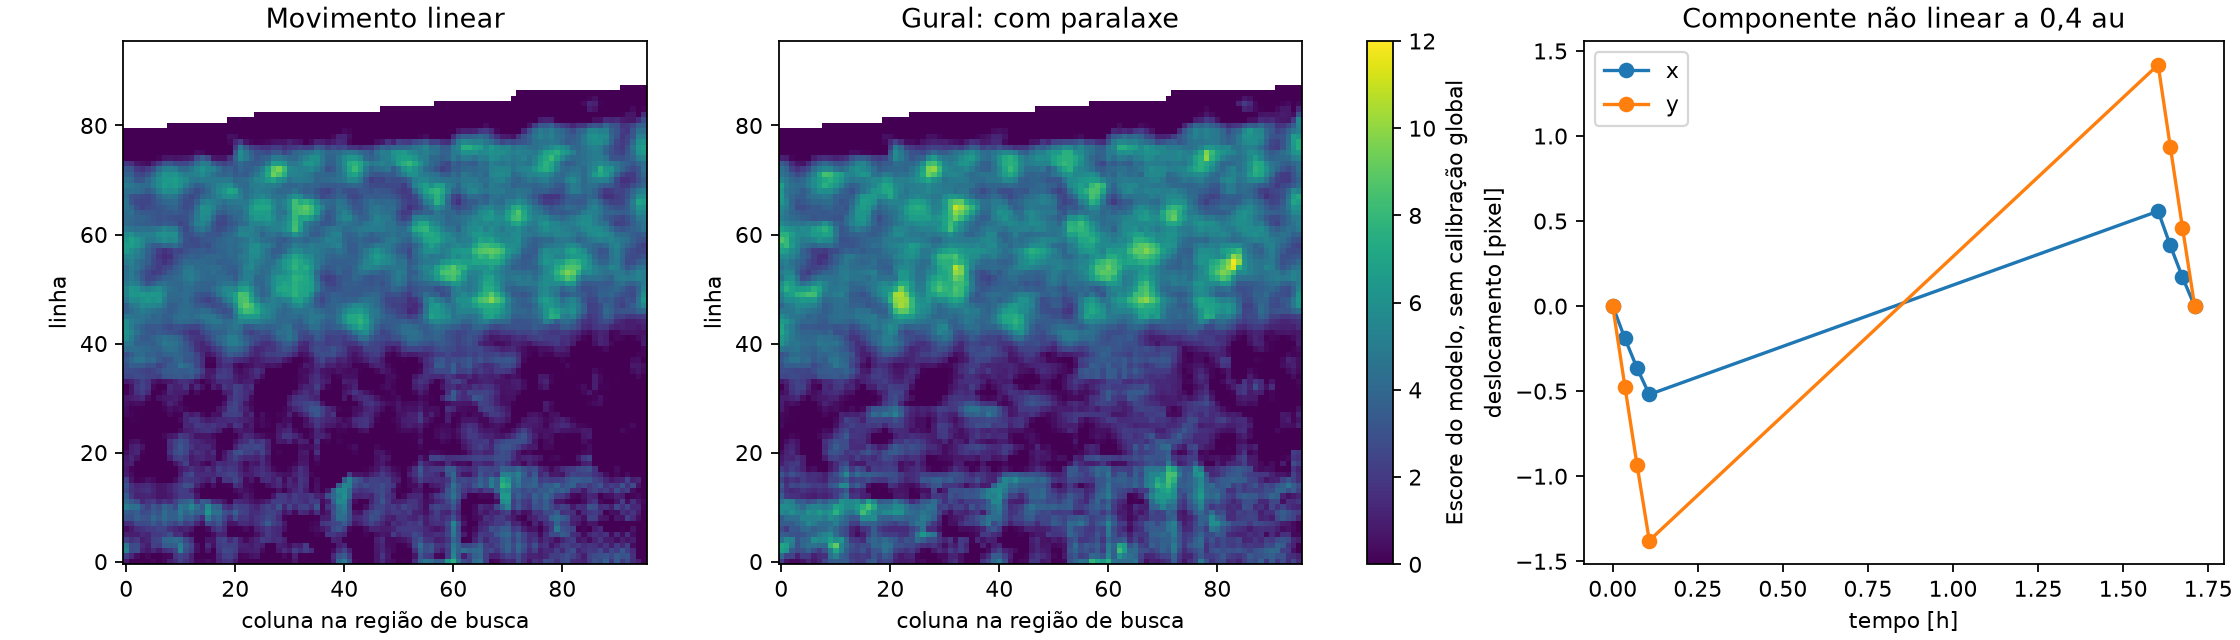

In [3]:
display(Image(filename=str(OUT / "comparison.png")))

## Empilhamento de catálogos

A entrada contém detecções individuais acima de um limiar, inclusive picos de
ruído. A busca projeta suas posições para uma época de referência e procura
agrupamentos. A coluna `votos` do algoritmo não é SNR, e várias detecções podem
vir da mesma exposição. Aqui contamos exposições distintas para diagnóstico.
Exigimos ao menos quatro para marcar um candidato para revisão, sem confirmar
um objeto físico. O pacote retorna até dez grupos por configuração.

Os tempos abaixo cobrem a etapa de busca/refinamento; o primeiro caso pode incluir
compilação JIT. Não são uma reprodução dos ganhos de velocidade do artigo.

In [4]:
rows = []
for label, result in report["stetzler"]["catalogs"].items():
    rows.append(
        {
            "catalogo": label,
            "picos_entrada": result["n_peaks"],
            "grupos_com_4_epocas": result.get("n_candidates_with_four_exposures", 0),
            "tempo_s_com_JIT": result.get("seconds_including_jit", 0),
            "recuperou_injecao": result.get("injected_track_recovered", False),
        }
    )
display(Table(rows=rows))
print("Presença da injeção no catálogo de entrada:")
display(
    JSON(report["stetzler"]["catalogs"]["linear_injection_snr2"]["input_catalog_truth_support"])
)

catalogo,picos_entrada,grupos_com_4_epocas,tempo_s_com_JIT,recuperou_injecao
str21,int64,int64,float64,bool
2.0,311,1,3.7613796980003826,False
3.0,150,0,0.19459793200076092,False
5.0,115,0,0.03398631399613805,False
linear_injection_snr2,315,1,0.27210143100091955,False


Presença da injeção no catálogo de entrada:


<IPython.core.display.JSON object>

## Interpretação e repetição

Há dois controles separados nos testes automatizados: a curvatura do template é
comparada a uma projeção 3D independente; o código original de Stetzler precisa
recuperar uma trajetória linear conhecida em um catálogo com ruído. Passar nesses
controles não implica detectar asteroides nos FITS reais.

Uma única injeção, em posição escolhida por boa cobertura de máscara, não mede
completude. As diferenças espectrais LVF, o modelo provisório de PSF, a estrutura
do fundo e a ausência de associação a efemérides continuam limitando a conclusão.

Para repetir os experimentos (alguns minutos em CPU):
```bash
uv run --extra literature spherex-tracking papers
```
Para executar os testes:
```bash
uv run --extra literature --extra dev pytest
```
Os catálogos e logs originais estão em `outputs/literature/`.
O tempo dos catálogos é relativo, em dias, não MJD.

In [5]:
display(JSON(report))

<IPython.core.display.JSON object>